In [ ]:
pip install pandas numpy scikit-learn xgboost lightgbm matplotlib seaborn


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, StackingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import SelectKBest, chi2
from imblearn.over_sampling import SMOTE

In [ ]:
from google.colab import files
uploaded = files.upload()

# Chargement du dataset
df = pd.read_csv("dataset_phishing.csv")

# Nettoyage des données
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})

Saving dataset_phishing.csv to dataset_phishing (1).csv


In [ ]:
# 📌 Séparer les features (X) et la cible (y)
X = df.drop(columns=['status'])  # Remplace 'Label' par le vrai nom de la colonne cible si différent
y = df['status']


In [ ]:
# 📌 3. SUPPRESSION DES FEATURES PEU INFORMATIVES
# Suppression des colonnes ayant une faible variance
from sklearn.feature_selection import VarianceThreshold
var_thresh = VarianceThreshold(threshold=0.01)  # Supprime les features avec une variance très faible
X = pd.DataFrame(var_thresh.fit_transform(X), columns=X.columns[var_thresh.get_support()])

In [ ]:
# Normalisation des données
scaler = StandardScaler()
X = scaler.fit_transform(X)


In [ ]:
# 📌 Diviser le dataset en train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
# 📌 Initialisation des modèles
models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, use_label_encoder=False, eval_metric='logloss', random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=100, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42)
}

# 📌 Entraînement et évaluation des modèles
results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred)

    results[name] = {"Accuracy": acc, "F1-score": f1, "AUC-ROC": roc_auc}

    print(f"\n🔹 Modèle: {name}")
    print(f"Accuracy: {acc:.4f}, F1-score: {f1:.4f}, AUC-ROC: {roc_auc:.4f}")
    print(classification_report(y_test, y_pred))


🔹 Modèle: Random Forest
Accuracy: 0.9593, F1-score: 0.9596, AUC-ROC: 0.9593
              precision    recall  f1-score   support

           0       0.97      0.95      0.96      1143
           1       0.95      0.97      0.96      1143

    accuracy                           0.96      2286
   macro avg       0.96      0.96      0.96      2286
weighted avg       0.96      0.96      0.96      2286



/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [17:24:55] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)



🔹 Modèle: XGBoost
Accuracy: 0.9676, F1-score: 0.9678, AUC-ROC: 0.9676
              precision    recall  f1-score   support

           0       0.97      0.96      0.97      1143
           1       0.96      0.97      0.97      1143

    accuracy                           0.97      2286
   macro avg       0.97      0.97      0.97      2286
weighted avg       0.97      0.97      0.97      2286

[LightGBM] [Info] Number of positive: 4572, number of negative: 4572
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004190 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4581
[LightGBM] [Info] Number of data points in the train set: 9144, number of used features: 65
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(



🔹 Modèle: LightGBM
Accuracy: 0.9637, F1-score: 0.9639, AUC-ROC: 0.9637
              precision    recall  f1-score   support

           0       0.97      0.96      0.96      1143
           1       0.96      0.97      0.96      1143

    accuracy                           0.96      2286
   macro avg       0.96      0.96      0.96      2286
weighted avg       0.96      0.96      0.96      2286


🔹 Modèle: AdaBoost
Accuracy: 0.9291, F1-score: 0.9292, AUC-ROC: 0.9291
              precision    recall  f1-score   support

           0       0.93      0.93      0.93      1143
           1       0.93      0.93      0.93      1143

    accuracy                           0.93      2286
   macro avg       0.93      0.93      0.93      2286
weighted avg       0.93      0.93      0.93      2286



/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [17:25:01] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Number of positive: 4572, number of negative: 4572
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004899 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4581
[LightGBM] [Info] Number of data points in the train set: 9144, number of used features: 65
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [17:25:11] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [17:25:12] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [17:25:13] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Number of positive: 3658, number of negative: 3657
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.010702 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4496
[LightGBM] [Info] Number of data points in the train set: 7315, number of used features: 64
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500068 -> initscore=0.000273
[LightGBM] [Info] Start training from score 0.000273


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


...

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Number of positive: 3658, number of negative: 3658
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003239 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4471
[LightGBM] [Info] Number of data points in the train set: 7316, number of used features: 64
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(



🔹 Stacking Classifier
Accuracy: 0.9659, F1-score: 0.9661, AUC-ROC: 0.9659
              precision    recall  f1-score   support

           0       0.97      0.96      0.97      1143
           1       0.96      0.97      0.97      1143

    accuracy                           0.97      2286
   macro avg       0.97      0.97      0.97      2286
weighted avg       0.97      0.97      0.97      2286


📊 Comparaison des modèles :
               Accuracy  F1-score   AUC-ROC
Random Forest  0.959318  0.959583  0.959318
XGBoost        0.967629  0.967770  0.967629
LightGBM       0.963692  0.963866  0.963692
AdaBoost       0.929134  0.929196  0.929134
Stacking       0.965879  0.966146  0.965879


<Figure size 1000x500 with 0 Axes>

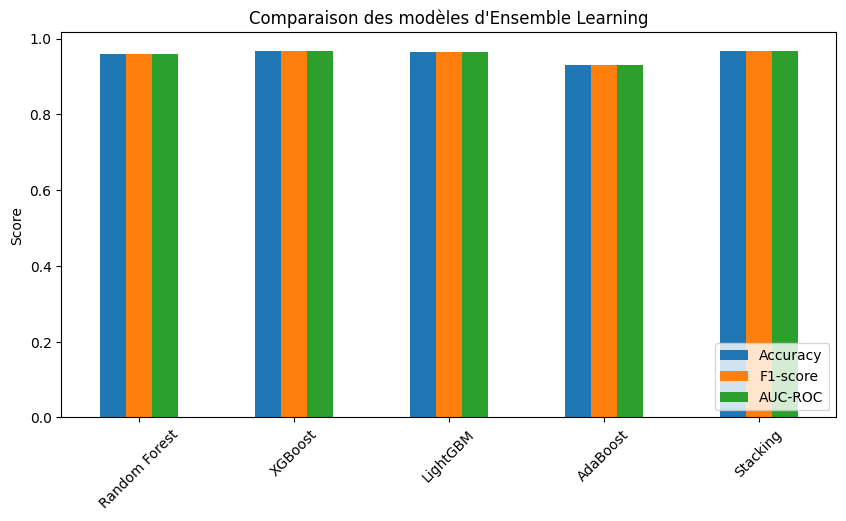

In [ ]:
# 📌 Stacking Classifier
stacking_model = StackingClassifier(
    estimators=[
        ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=100, use_label_encoder=False, eval_metric='logloss', random_state=42)),
        ('lgbm', LGBMClassifier(n_estimators=100, random_state=42))
    ],
    final_estimator=LogisticRegression(),
    cv=5
)

stacking_model.fit(X_train, y_train)
y_pred_stack = stacking_model.predict(X_test)

acc_stack = accuracy_score(y_test, y_pred_stack)
f1_stack = f1_score(y_test, y_pred_stack)
roc_auc_stack = roc_auc_score(y_test, y_pred_stack)

results["Stacking"] = {"Accuracy": acc_stack, "F1-score": f1_stack, "AUC-ROC": roc_auc_stack}

print("\n🔹 Stacking Classifier")
print(f"Accuracy: {acc_stack:.4f}, F1-score: {f1_stack:.4f}, AUC-ROC: {roc_auc_stack:.4f}")
print(classification_report(y_test, y_pred_stack))

# 📌 Comparaison des performances
df_results = pd.DataFrame(results).T
print("\n📊 Comparaison des modèles :")
print(df_results)

# 📌 Visualisation des résultats
plt.figure(figsize=(10, 5))
df_results.plot(kind='bar', figsize=(10, 5))
plt.title("Comparaison des modèles d'Ensemble Learning")
plt.xticks(rotation=45)
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.show()

In [ ]:
!pip uninstall -y numpy
!pip install numpy==1.23.5  # Installer une version stable compatible
!pip install --upgrade catboost  # Réinstaller CatBoost


Found existing installation: numpy 1.26.4
Uninstalling numpy-1.26.4:
  Successfully uninstalled numpy-1.26.4
  Using cached numpy-1.23.5-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (2.3 kB)
Using cached numpy-1.23.5-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (17.1 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
albumentations 2.0.5 requires numpy>=1.24.4, but you have numpy 1.23.5 which is incompatible.
jax 0.5.2 requires numpy>=1.25, but you have numpy 1.23.5 which is incompatible.
xarray 2025.1.2 requires numpy>=1.24, but you have numpy 1.23.5 which is incompatible.
tensorflow 2.18.0 requires numpy<2.1.0,>=1.26.0, but you have numpy 1.23.5 which is incompatible.
jaxlib 0.5.1 requires numpy>=1.25, but you have numpy 1.23.5 which is incompatible.
treescope 0.1.9 requires numpy>=1.25.2, but you have numpy 1.23.5 which 

In [ ]:
!pip uninstall -y numpy catboost
!pip install numpy catboost



from catboost import CatBoostClassifier

# 📌 Suppression d'AdaBoost du dictionnaire des modèles
models.pop("AdaBoost", None)

# 📌 Nouveau Stacking sans AdaBoost
stacking_model = StackingClassifier(
    estimators=[
        ('rf', RandomForestClassifier(n_estimators=200, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=200, use_label_encoder=False, eval_metric='logloss', random_state=42)),
        ('lgbm', LGBMClassifier(n_estimators=200, random_state=42)),
        ('catboost', CatBoostClassifier(iterations=200, depth=6, learning_rate=0.05, random_seed=42, verbose=0))
    ],
    final_estimator=XGBClassifier(n_estimators=100, use_label_encoder=False, eval_metric='logloss', random_state=42),
    cv=5
)

# Entraînement du modèle Stacking optimisé
stacking_model.fit(X_train, y_train)
y_pred_stack = stacking_model.predict(X_test)

# Évaluation
acc_stack = accuracy_score(y_test, y_pred_stack)
f1_stack = f1_score(y_test, y_pred_stack)
roc_auc_stack = roc_auc_score(y_test, y_pred_stack)

# Ajout des nouveaux résultats
results["Stacking Optimisé"] = {"Accuracy": acc_stack, "F1-score": f1_stack, "AUC-ROC": roc_auc_stack}

print("\n🔹 Stacking sans AdaBoost")
print(f"Accuracy: {acc_stack:.4f}, F1-score: {f1_stack:.4f}, AUC-ROC: {roc_auc_stack:.4f}")


Found existing installation: numpy 1.23.5
Uninstalling numpy-1.23.5:
  Successfully uninstalled numpy-1.23.5
Found existing installation: catboost 1.2.7
Uninstalling catboost-1.2.7:
  Successfully uninstalled catboost-1.2.7
  Using cached numpy-2.2.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
  Using cached catboost-1.2.7-cp311-cp311-manylinux2014_x86_64.whl.metadata (1.2 kB)
  Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached catboost-1.2.7-cp311-cp311-manylinux2014_x86_64.whl (98.7 MB)
Using cached numpy-1.26.4-cp311-cp311-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.3 MB)


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [17:25:57] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Number of positive: 4572, number of negative: 4572
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004067 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4581
[LightGBM] [Info] Number of data points in the train set: 9144, number of used features: 65
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [17:26:18] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [17:26:19] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [17:26:20] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [17:26:21] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 an

[LightGBM] [Info] Number of positive: 3658, number of negative: 3657
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003306 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4496
[LightGBM] [Info] Number of data points in the train set: 7315, number of used features: 64
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500068 -> initscore=0.000273
[LightGBM] [Info] Start training from score 0.000273


...

[LightGBM] [Info] Number of positive: 3657, number of negative: 3658
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003322 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4483
[LightGBM] [Info] Number of data points in the train set: 7315, number of used features: 64
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499932 -> initscore=-0.000273
[LightGBM] [Info] Start training from score -0.000273


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[LightGBM] [Info] Number of positive: 3658, number of negative: 3658
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003305 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4471
[LightGBM] [Info] Number of data points in the train set: 7316, number of used features: 64
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [17:26:37] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(



🔹 Stacking sans AdaBoost
Accuracy: 0.9641, F1-score: 0.9643, AUC-ROC: 0.9641
